# Comparing the four OCT denoising implementations: PSNR, SSIM and EPI

This notebook puts the four denoisers in this repository side by side on the **Duke SD-OCT 2012** dataset
(`Sparsity_SDOCT_DATASET_2012`). It scores all of them with the same metric code, against the same reference, after
tuning each one with the same procedure.

| Short name | Method | Paper | Implementation used |
|---|---|---|---|
| **TGV** | Second-order total generalised variation decomposition, split Bregman | Duan et al., *BSPC* 24 (2016) | `Denoising_..._decomposition/src/tgv.py` (imported unchanged) |
| **NLM** | Non-local means with a fractional compact finite-difference (FCFDS) patch kernel | Chen & Gao, *Micromachines* 13 (2022) | `NLM_PSO_Denoising/NLM_Denoising.ipynb` (ported) |
| **Wavelet-PSO** | Modified soft-threshold wavelet shrinkage, parameters chosen by particle swarm optimisation | Subhedar et al., *TS* 40(3) (2023) | `NLM_PSO_Denoising/PSO_Denoising.ipynb` (ported, without its log transform; see section 1) |
| **K-SVD** | Sparse coding (OMP) over a K-SVD global dictionary, with per-image noise estimation | Zhang et al., *Opt. Express* 30(4) (2022) | `OMP_KSVD/denoising.ipynb` (ported; uses its saved dictionary) |
| **MSBTD** | Multiscale sparsity-based tomographic denoising | Fang et al., *BOE* 3(5) (2012) | precomputed `*_MSBTD result.mat` shipped with the dataset (**benchmark**) |

`methods.py` holds the ports: the notebook code is copied unchanged, except that module-level constants became keyword
arguments so the strength parameters can be tuned from here. The one algorithmic change is that the wavelet port
skips the paper's log transform, because the data is already log-compressed (section 1). A sanity check during development reproduced the source
notebooks exactly (NLM on Image 1: 27.5024 dB; K-SVD on subject 15: 29.13 dB).

Every figure shows, for each B-scan: the **noisy** raw scan, the **clean averaged** scan (the reference), the
**MSBTD** benchmark, and the output of each of the four implementations.

## 1. What "fair" means here

Each implementation came with parameters chosen under its own protocol, so its default numbers can't be compared
directly:

| Method | How its notebook/script set its parameters | Problem for a comparison |
|---|---|---|
| TGV | Grid search on a **synthetic phantom** with Gaussian noise (variance 0.04) | Never tuned on real speckle |
| NLM | $h_f$ grid on **Image 1** only, PSNR vs averaged | Different tuning image from the others |
| Wavelet-PSO | PSO fitness = PSNR vs the **noisy input**, single-level DWT, $K\in[1,1.5]$, $\log(1+z)$ before the DWT | The fitness rewards leaving the noise in. PSO lands on the corner of the box that changes the image least (≈ 19 dB vs averaged). The log is taken of data that is already log-compressed (see below) |
| K-SVD | Fixed paper constants ($C=1.15$, $\lambda=30/\sigma$) | Never tuned on this data |

To even this out, every method goes through the same protocol:

1. **Same data split.** The K-SVD dictionary was learned from the *averaged* images of subjects 1–12, so subjects
   **13–17** have not been seen by any method. They form the **held-out test set**. Parameters are tuned on four
   images from the training subjects, **{1, 4, 7, 10}**. The other eight training subjects
   **{2, 3, 5, 6, 8, 9, 11, 12}** form a second evaluation set. None of the methods was tuned on them, but K-SVD's
   dictionary saw their averaged images, so they are reported separately.
2. **Same tuning objective.** Each method's parameters maximise the **mean PSNR against the averaged image over the
   four tuning images**. Everything is chosen once and then frozen for all test images. Nothing is tuned on a test
   image.
3. **Same tuning freedom.** Every method gets its **two main strength parameters** searched. The structural settings
   from each paper (patch size, search window, wavelet family, dictionary) stay as published. The search ranges are
   checked so that the optimum is **inside** the range, not on its edge.
4. **Same input and output.** All methods take the raw 8-bit B-scan and return an image on the 0–255 scale, clipped.
   Internal rescaling belongs to the method itself (scaling to [0, 1] in TGV). No method adds a log transform,
   because the data is already log-compressed (see below).
5. **Same metrics.** One implementation of PSNR, SSIM and EPI (section 3) scores every output, including MSBTD.

| Method | Parameters searched | Search space | Fixed (from the paper / its notebook) |
|---|---|---|---|
| TGV | $\alpha_0=\alpha_1=\alpha$ (TGV weight), $\beta$ (texture weight) | $\alpha\in\{0.05,0.1,0.2,0.3,0.45\}$, $\beta\in\{0.1,0.3,1.0\}$ | $\lambda_{1,2,3}=2$, tol $10^{-3}$, ≤ 300 iterations |
| NLM | $h_f$ (normalised filtering strength), FCFDS order $\alpha$ | $h_f\in\{2.0,2.4,2.8,3.6,4.6\}$, $\alpha\in\{0.1,0.3,0.6\}$ | 21×21 search window, 7×7 patch, $N=4$ taps, $\phi_x=4$ |
| Wavelet-PSO | decomposition level $L$, threshold multiplier $K$ (+ shape $\alpha,\beta$ found by PSO, as in the paper) | $L\in\{1,\dots,6\}$; PSO over $\alpha\in[0,0.5]$, $\beta\in[1,5]$, $K\in[0.5,4]$ | db2 wavelet, hierarchical threshold $L_d=\ln(e+d-1)$, **no** log transform (see below) |
| K-SVD | OMP error multiplier $C$, fidelity scale $c$ in $\lambda=c/\sigma$ | $C\in\{1.15,1.35,1.6,1.9,2.3\}$, $c\in\{3,10,30\}$ | 8×8 patches, 64×256 dictionary, ≤ 12 atoms, GLCM/Laplacian $\sigma$ estimate |

For Wavelet-PSO the decomposition level is part of the search. With the paper's single level, the method can't
reach the coarser scales where most of the speckle energy lives. Section 4 shows this costs about 5.5 dB, so leaving the
level fixed would decide the comparison before it started. Section 8 runs every method again with its
**original** settings, so the effect of balancing is visible.

**No log transform for Wavelet-PSO.** The paper (its Fig. 2) takes $\log(1+z)$ before the DWT and $e^x-1$ after it,
to turn multiplicative speckle into additive noise. That only makes sense for linear-intensity data, and the Duke
B-scans are already log-compressed display images. The noise in `raw − averaged` hardly grows with brightness (the
slope of log σ against log μ is 0.13–0.31 over all 17 cases, where linear speckle gives about 1), and it is skewed
towards dark values (−0.23 to −0.47, where linear speckle is skewed towards bright values). The TGV implementation
reached the same conclusion (`src/io_utils.py`), and TGV, NLM and K-SVD all work on the stored values. A second log
squashes the bright layers and stretches the dark background, and the final $e^x-1$ returns a geometric mean, so the
output comes out 9–19 grey levels too dark on the tuning images. On the held-out cases that cost about 5.6 dB PSNR
and halved EPI. The wavelet port therefore runs with `log_domain=True` (no log), the same setting as TGV. Section 8
still runs the original pipeline, log included.

**MSBTD is not tuned by us.** It is the precomputed result shipped with the dataset. Note that, per the dataset's
`Readme.txt`, MSBTD learns its dictionaries from the *averaged* images. It has seen a high-SNR scan of the same
eye, which none of the four implementations here gets at test time.

## 2. Setup

In [16]:
import os
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io as sio
import tifffile
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import methods as M

DATA_DIR = Path("..") / "Sparsity_SDOCT_DATASET_2012"
OUT_DIR = Path("outputs")
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
(OUT_DIR / "denoised").mkdir(parents=True, exist_ok=True)

TUNE_IDS = [1, 4, 7, 10]                  # parameter tuning (training subjects)
TEST_IDS = [13, 14, 15, 16, 17]           # held out from everything (primary results)
OTHER_IDS = [2, 3, 5, 6, 8, 9, 11, 12]    # untuned, but seen by the K-SVD dictionary (secondary results)
EVAL_IDS = TEST_IDS + OTHER_IDS

METHODS = ["TGV", "NLM", "Wavelet-PSO", "K-SVD"]
DISPATCH = {"TGV": "TGV", "NLM": "NLM", "Wavelet-PSO": "Wavelet", "K-SVD": "KSVD"}
BENCH = "MSBTD"
ALL = ["Noisy", BENCH] + METHODS
COLORS = {"Noisy": "#9e9e9e", BENCH: "#4d4d4d", "TGV": "#1f77b4", "NLM": "#ff7f0e",
          "Wavelet-PSO": "#2ca02c", "K-SVD": "#d62728"}

# NumPy releases the GIL in the heavy loops, so threads run TGV / NLM / wavelet in parallel. K-SVD's OMP is
# already multithreaded through BLAS, and running many copies at once is slower than running them in turn.
N_WORKERS = min(8, os.cpu_count() or 1)
WORKERS = {"TGV": N_WORKERS, "NLM": N_WORKERS, "Wavelet-PSO": N_WORKERS, "K-SVD": 2}
LOG = OUT_DIR / "run_log.txt"
LOG.write_text("")
T_START = time.time()


def log(msg):
    line = f"[{time.time() - T_START:6.0f}s] {msg}"
    print(line, flush=True)
    with open(LOG, "a", encoding="utf-8") as fh:
        fh.write(line + "\n")


def parallel(method, fn, jobs):
    # jobs: list of argument tuples; returns results in order
    with ThreadPoolExecutor(WORKERS[method]) as ex:
        return list(ex.map(lambda a: fn(*a), jobs))


plt.rcParams.update({"figure.dpi": 100, "image.cmap": "gray"})
log(f"dataset: {DATA_DIR.resolve()}, threads: {N_WORKERS}")

[     0s] dataset: C:\Users\sidhe\oct_denoising\Sparsity_SDOCT_DATASET_2012, threads: 8


## 2.1 Load the dataset

Only the registered raw / averaged pair in each numbered case folder is used. The `Distant/` and `Unregistered/`
sub-folders of cases 1 and 2 hold other acquisitions that are not aligned with the raw scan. All 17 MSBTD results
(`DA` in the `.mat` files) have the same size as their raw scan.

In [17]:
def load_case(cid):
    d = DATA_DIR / str(cid)
    raw = tifffile.imread(next(d.glob("*Raw Image.tif"))).astype(np.float64)
    ref = tifffile.imread(next(d.glob("*Averaged Image.tif"))).astype(np.float64)
    mat = sio.loadmat(next(d.glob("*MSBTD*.mat")))
    msbtd = next(v for k, v in mat.items() if not k.startswith("__")).astype(np.float64)
    assert raw.shape == ref.shape == msbtd.shape
    return raw, ref, msbtd


RAW, REF, MSB = {}, {}, {}
for cid in range(1, 18):
    RAW[cid], REF[cid], MSB[cid] = load_case(cid)

overview = pd.DataFrame([{"case": cid, "set": "tune" if cid in TUNE_IDS else "test" if cid in TEST_IDS else "other",
                          "shape": f"{RAW[cid].shape[0]}x{RAW[cid].shape[1]}",
                          **{f"noisy {k}": v for k, v in M.all_metrics(REF[cid], RAW[cid]).items()},
                          **{f"MSBTD {k}": v for k, v in M.all_metrics(REF[cid], MSB[cid]).items()}}
                         for cid in RAW]).set_index("case")
display(overview.round(4))

,set,shape,noisy PSNR,noisy SSIM,noisy EPI,MSBTD PSNR,MSBTD SSIM,MSBTD EPI
case,,,,,,,,
1,tune,520x970,17.2819,0.0662,0.0471,26.7869,0.5847,0.3949
2,other,530x980,17.9002,0.0835,0.1754,28.0406,0.6293,0.6822
3,other,508x960,17.8048,0.0742,0.0618,27.6563,0.6174,0.3992
4,tune,552x990,17.5636,0.0726,0.0897,25.5772,0.6107,0.4501
5,other,550x950,18.2835,0.0786,0.0263,26.9810,0.6406,0.2339
6,other,540x950,18.0775,0.0705,0.0744,27.8974,0.5819,0.3073
7,tune,530x980,18.2872,0.0804,0.0676,29.9691,0.6431,0.4447
8,other,540x940,18.2249,0.0857,0.1591,28.6256,0.7059,0.6295
9,other,510x960,17.0012,0.0695,0.1017,23.0146,0.4369,0.3445


## 3. The metrics

All three are **full-reference**: they compare a denoised image $\hat x$ with the registered multi-frame **averaged**
B-scan $x$ of the same location. The averaged image is the dataset's clean target, but it is not true ground truth.
It still carries a small grain floor (σ ≈ 4.5 grey levels by the K-SVD notebook's Laplacian estimator), which caps
PSNR at roughly 35 dB.

* **PSNR** (peak signal-to-noise ratio, dB): $10\log_{10}\big(255^2/\mathrm{MSE}(x,\hat x)\big)$. It measures overall
  pixel-wise fidelity and is dominated by large errors. Since most of a raw B-scan's error is speckle, PSNR mainly
  rewards **noise removal**. Higher is better; +3 dB means the MSE halved.
* **SSIM** (structural similarity, 0–1): mean over the image of local luminance × contrast × structure agreement
  (Wang et al. 2004; 11×11 Gaussian window, σ = 1.5, fixed data range 255). It is more sensitive than PSNR to
  whether **local structure and contrast** survive. A raw scan scores ≈ 0.07 here because speckle destroys the local
  structure term.
* **EPI** (edge preservation index, 0–1): the correlation coefficient between the Sobel gradient-magnitude maps of
  reference and output,
  $\mathrm{EPI}=\frac{\sum(\nabla x-\overline{\nabla x})(\nabla\hat x-\overline{\nabla\hat x})}{\sqrt{\sum(\nabla x-\overline{\nabla x})^2\sum(\nabla\hat x-\overline{\nabla\hat x})^2}}$.
  It is high when the output has edges **in the same places and with the same relative strength** as the reference.
  It drops for two opposite reasons: residual speckle (spurious edges) and over-smoothing (missing layer boundaries).
  The Sobel operator is used rather than the Laplacian. The K-SVD notebook (§7.7) showed that the Laplacian version
  responds to single-pixel grain and even ranks the noisy image above the denoised ones on this data.

The three metrics are complementary. PSNR asks *how much noise is gone*, SSIM *does local structure look right*, and EPI
*are the layer boundaries where they should be*. A method can trade one for another, and the tuning curves in
section 4 show that trade-off for each method.

## 4. Tuning every method with the same protocol

`run_grid` evaluates every parameter combination on the four tuning images, in parallel. It records mean
PSNR / SSIM / EPI and picks the combination with the highest mean PSNR. `check_interior` warns if the chosen value of a
strength parameter sits on the edge of its range, which would mean the range was too narrow.

In [18]:
def run_grid(method, grid):
    keys = list(grid)
    combos = [dict(zip(keys, vals)) for vals in product(*grid.values())]
    jobs = [(DISPATCH[method], RAW[cid], REF[cid], p) for p in combos for cid in TUNE_IDS]
    out = parallel(method, M.score, jobs)
    rows = []
    for i, p in enumerate(combos):
        res = out[i * len(TUNE_IDS):(i + 1) * len(TUNE_IDS)]
        rows.append({**p, **{m: np.mean([r[0][m] for r in res]) for m in ("PSNR", "SSIM", "EPI")},
                     "time_s": np.mean([r[1] for r in res])})
    return pd.DataFrame(rows)


def check_interior(df, grid):
    best = df.loc[df["PSNR"].idxmax()]
    for k, vals in grid.items():
        if len(vals) > 1 and best[k] in (min(vals), max(vals)):
            spread = df.groupby(k)["PSNR"].max()
            print(f"  note: best {k}={best[k]} is on the edge of {vals}; "
                  f"best PSNR per {k}: {spread.round(3).to_dict()}")
    return best


GRIDS = {
    "TGV": {"alpha": [0.05, 0.1, 0.2, 0.3, 0.45], "beta": [0.1, 0.3, 1.0]},
    "NLM": {"h_factor": [2.0, 2.4, 2.8, 3.6, 4.6], "alpha": [0.1, 0.3, 0.6]},
    "K-SVD": {"omp_C": [1.15, 1.35, 1.6, 1.9, 2.3], "lambda_scale": [3.0, 10.0, 30.0]},
}

t0 = time.time()
TUNING, BEST = {}, {}
for method, grid in GRIDS.items():
    log(f"tuning {method}: {np.prod([len(v) for v in grid.values()])} combinations x {len(TUNE_IDS)} images")
    TUNING[method] = run_grid(method, grid)
    best = check_interior(TUNING[method], grid)
    BEST[method] = {k: float(best[k]) for k in grid}
    log(f"{method:6s} best {BEST[method]}  ->  PSNR {best['PSNR']:.3f}  SSIM {best['SSIM']:.4f}  EPI {best['EPI']:.4f}")
log(f"grid tuning done in {time.time() - t0:.0f} s")

[     3s] tuning TGV: 15 combinations x 4 images
  note: best beta=1.0 is on the edge of [0.1, 0.3, 1.0]; best PSNR per beta: {0.1: 27.506, 0.3: 27.512, 1.0: 27.512}
[   305s] TGV    best {'alpha': 0.2, 'beta': 1.0}  ->  PSNR 27.512  SSIM 0.6863  EPI 0.5408
[   305s] tuning NLM: 15 combinations x 4 images
[   528s] NLM    best {'h_factor': 2.4, 'alpha': 0.3}  ->  PSNR 27.512  SSIM 0.6662  EPI 0.4960
[   528s] tuning K-SVD: 15 combinations x 4 images
  note: best lambda_scale=3.0 is on the edge of [3.0, 10.0, 30.0]; best PSNR per lambda_scale: {3.0: 27.632, 10.0: 27.627, 30.0: 27.606}
[   674s] K-SVD  best {'omp_C': 1.6, 'lambda_scale': 3.0}  ->  PSNR 27.632  SSIM 0.6810  EPI 0.5416
[   674s] grid tuning done in 671 s


**Wavelet-PSO.** The paper's own optimiser tunes this method. PSO searches $(\alpha, \beta, K)$ separately at every
decomposition level $L = 1,\dots,6$, using the same fitness as everyone else: mean PSNR against the averaged image
over the tuning images. The best level wins. The swarm is smaller than the paper's 100 particles (30 particles × 15
iterations). Its convergence curves below flatten well before the last iteration, so the smaller swarm doesn't
change the result.

Without the log transform, PSO drives $\alpha$ to 0 and $\beta$ to its lower bound of 1, so the modified threshold
ends up close to plain soft thresholding. Widening the range to $\beta \ge 0.01$ during development changed the
held-out PSNR by only +0.07 dB, so the paper's range is kept.

In [19]:
WAVELET_BOUNDS = {"alpha": (0.0, 0.5), "beta": (1.0, 5.0), "K": (0.5, 4.0)}
LEVELS = [1, 2, 3, 4, 5, 6]

t0 = time.time()
tune_imgs, tune_refs = [RAW[c] for c in TUNE_IDS], [REF[c] for c in TUNE_IDS]
log(f"tuning Wavelet-PSO: levels {LEVELS}")
pso_runs = parallel("Wavelet-PSO", M.pso_tune_wavelet, [(L, tune_imgs, tune_refs, WAVELET_BOUNDS) for L in LEVELS])
rows = []
for run in pso_runs:
    p = {k: run[k] for k in ("level", "alpha", "beta", "K")}
    p["level"] = int(p["level"])
    m = [M.all_metrics(REF[c], M.wavelet_mst(RAW[c], **p)) for c in TUNE_IDS]
    rows.append({**p, **{k: np.mean([x[k] for x in m]) for k in ("PSNR", "SSIM", "EPI")}})
TUNING["Wavelet-PSO"] = pd.DataFrame(rows)
best = TUNING["Wavelet-PSO"].loc[TUNING["Wavelet-PSO"]["PSNR"].idxmax()]
BEST["Wavelet-PSO"] = {"level": int(best["level"]), **{k: float(best[k]) for k in ("alpha", "beta", "K")}}
display(TUNING["Wavelet-PSO"].round(4))
lo, hi = WAVELET_BOUNDS["K"]
if not lo + 1e-3 < BEST["Wavelet-PSO"]["K"] < hi - 1e-3:
    print("  note: K is on the edge of its PSO range")
log(f"Wavelet-PSO best {BEST['Wavelet-PSO']}  ({time.time() - t0:.0f} s)")

[   675s] tuning Wavelet-PSO: levels [1, 2, 3, 4, 5, 6]


,level,alpha,beta,K,PSNR,SSIM,EPI
0,1,0.5000,1.0000,1.2241,19.2731,0.1314,0.0712
1,2,0.0299,1.9005,2.3336,21.7184,0.3547,0.1862
2,3,0.0169,1.2181,2.6881,22.9659,0.5740,0.3000
3,4,0.0270,1.0000,1.8275,23.1587,0.6189,0.3195
4,5,0.0312,1.0000,1.6919,23.1902,0.6179,0.2851
5,6,0.0334,1.0000,1.6695,23.1938,0.6165,0.2755


[   782s] Wavelet-PSO best {'level': 6, 'alpha': 0.033425114212346486, 'beta': 1.0, 'K': 1.6694867525119887}  (108 s)


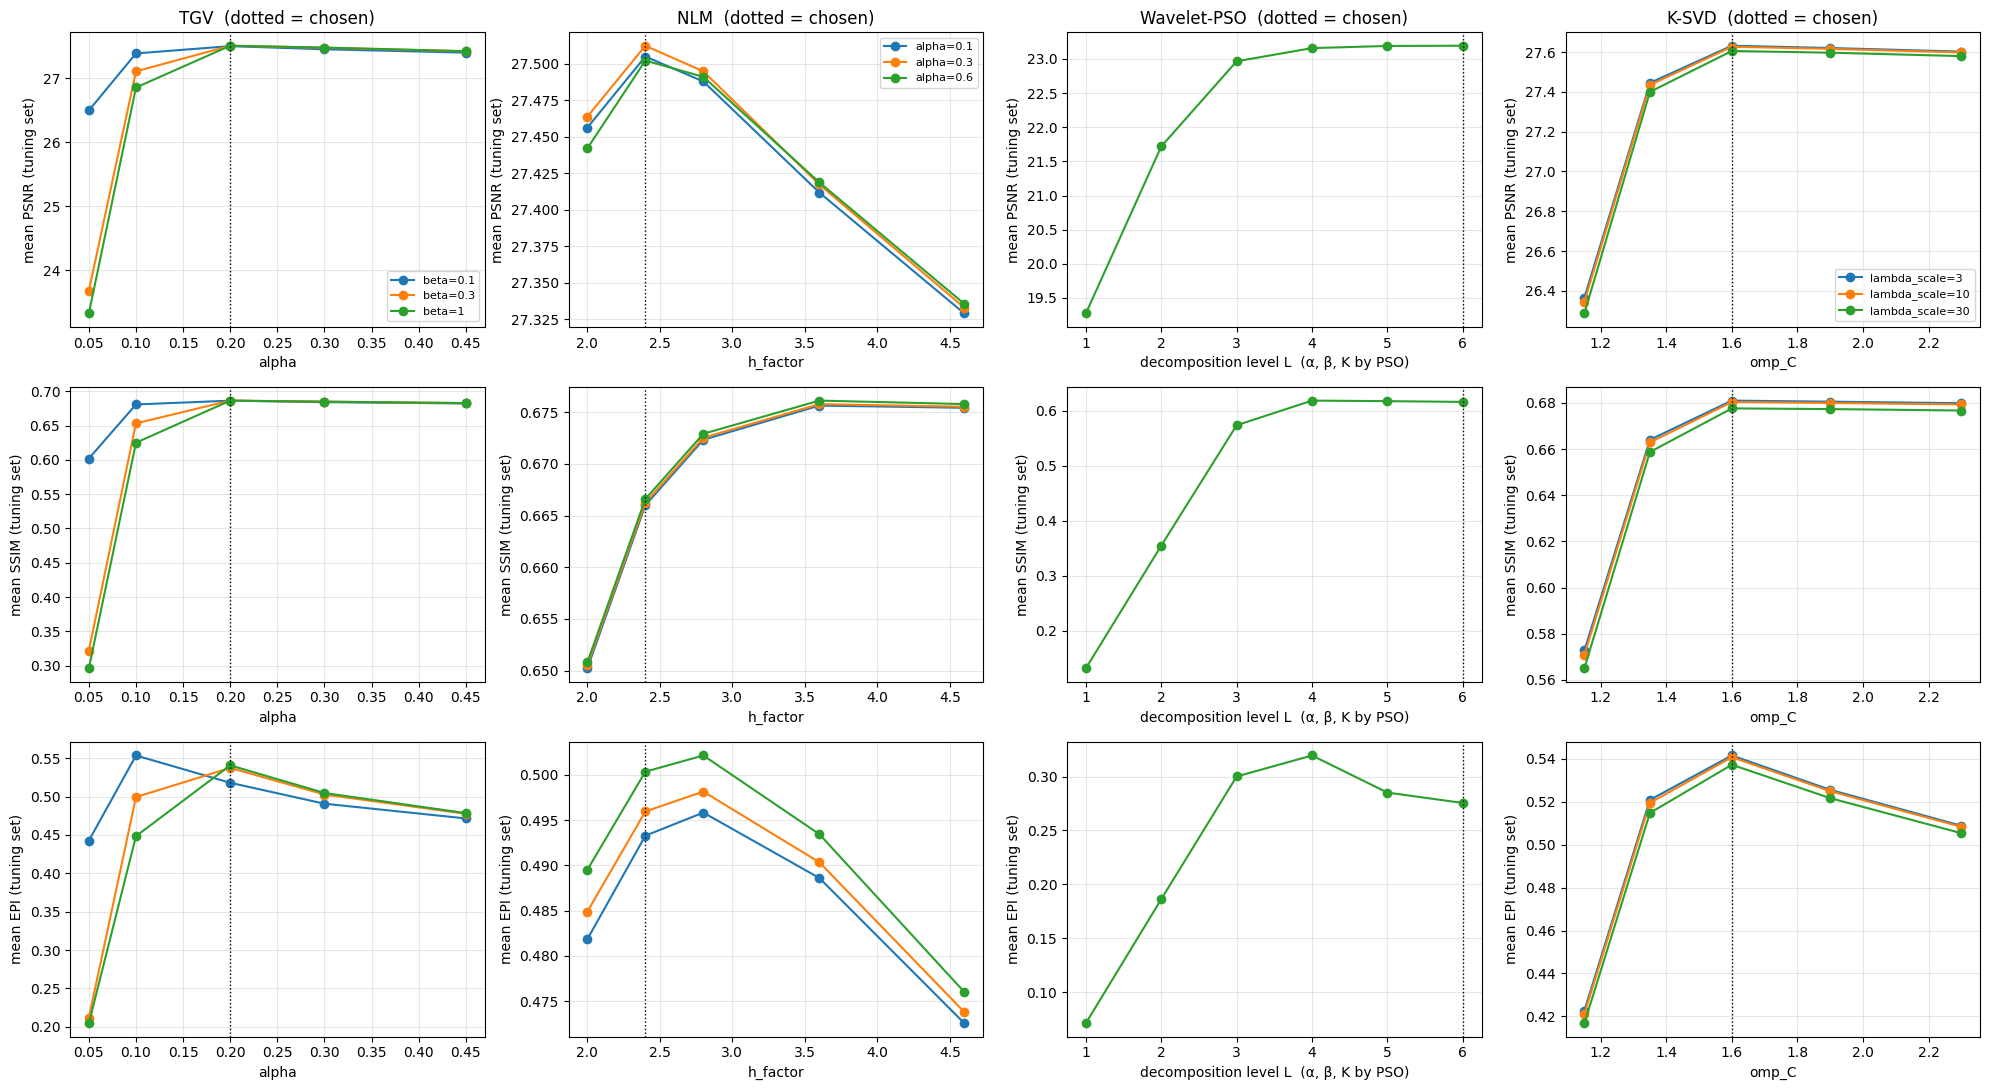

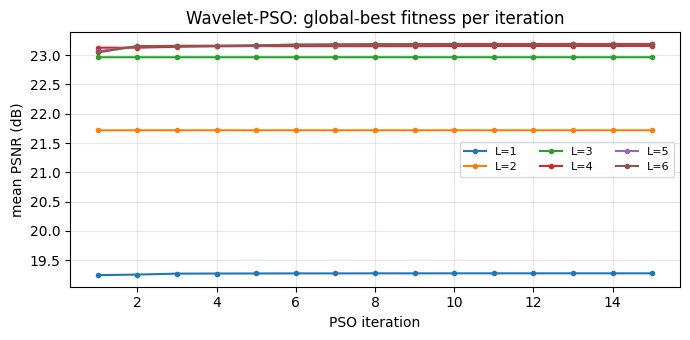

,chosen parameters
method,
TGV,"alpha=0.2, beta=1"
NLM,"h_factor=2.4, alpha=0.3"
Wavelet-PSO,"level=6, alpha=0.0334251, beta=1, K=1.66949"
K-SVD,"omp_C=1.6, lambda_scale=3"


In [20]:
fig, axes = plt.subplots(3, 4, figsize=(20, 11))
curves = {"TGV": ("alpha", "beta"), "NLM": ("h_factor", "alpha"), "K-SVD": ("omp_C", "lambda_scale")}
for col, method in enumerate(METHODS):
    df = TUNING[method]
    for row, metric in enumerate(["PSNR", "SSIM", "EPI"]):
        ax = axes[row, col]
        if method == "Wavelet-PSO":
            ax.plot(df["level"], df[metric], "o-", color=COLORS[method])
            ax.set_xlabel("decomposition level L  (α, β, K by PSO)")
            ax.axvline(BEST[method]["level"], color="k", ls=":", lw=1)
        else:
            x, line = curves[method]
            for v, grp in df.groupby(line):
                ax.plot(grp[x], grp[metric], "o-", label=f"{line}={v:g}")
            ax.set_xlabel(x)
            ax.axvline(BEST[method][x], color="k", ls=":", lw=1)
            if row == 0:
                ax.legend(fontsize=8)
        ax.set_ylabel(f"mean {metric} (tuning set)")
        ax.grid(alpha=0.3)
        if row == 0:
            ax.set_title(f"{method}  (dotted = chosen)")
plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "tuning_curves.png", dpi=110)
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
for run in pso_runs:
    ax.plot(range(1, len(run["history"]) + 1), run["history"], marker=".", label=f"L={run['level']}")
ax.set(title="Wavelet-PSO: global-best fitness per iteration", xlabel="PSO iteration", ylabel="mean PSNR (dB)")
ax.legend(ncol=3, fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

params_table = pd.DataFrame([{"method": m, "chosen parameters": ", ".join(f"{k}={v:g}" for k, v in BEST[m].items())}
                             for m in METHODS]).set_index("method")
display(params_table)

*(results discussion is written after the first run)*

## 5. Denoise every evaluation image with the frozen parameters

All 13 non-tuning images go through every method with the parameters chosen above. Runtimes are wall-clock seconds per
B-scan measured while several images run in parallel threads, so they are inflated compared with an idle machine.

In [21]:
t0 = time.time()
OUTS = {cid: {"Noisy": RAW[cid], BENCH: MSB[cid]} for cid in EVAL_IDS}
TIMES = []
for m in METHODS:
    log(f"denoising {len(EVAL_IDS)} evaluation images with {m}")
    res = parallel(m, M.denoise, [(DISPATCH[m], RAW[cid], BEST[m]) for cid in EVAL_IDS])
    for cid, (img, dt) in zip(EVAL_IDS, res):
        OUTS[cid][m] = img
        TIMES.append({"method": m, "case": cid, "seconds": dt})
log(f"denoised {len(EVAL_IDS)} images x {len(METHODS)} methods in {time.time() - t0:.0f} s")

records = [{"case": cid, "set": "test" if cid in TEST_IDS else "other", "method": name,
            **M.all_metrics(REF[cid], img)}
           for cid in EVAL_IDS for name, img in OUTS[cid].items()]
RESULTS = pd.DataFrame(records)
RESULTS.to_csv(OUT_DIR / "metrics_per_image.csv", index=False)

for cid in EVAL_IDS:
    for m in METHODS:
        tifffile.imwrite(OUT_DIR / "denoised" / f"case{cid:02d}_{m.replace('-', '_')}.tif",
                         np.round(OUTS[cid][m]).astype(np.uint8))

[   784s] denoising 13 evaluation images with TGV
[   847s] denoising 13 evaluation images with NLM
[   889s] denoising 13 evaluation images with Wavelet-PSO
[   889s] denoising 13 evaluation images with K-SVD
[   918s] denoised 13 images x 4 methods in 133 s


## 6. Visual comparison on the held-out test images

For each held-out B-scan, the top row shows the full image and the bottom row a zoom on the retinal layers. The zoom
is centred on the brightest band (the RPE) of the averaged image. All panels share the same 0–255 grey scale. Each
title gives PSNR / SSIM / EPI against the averaged image.

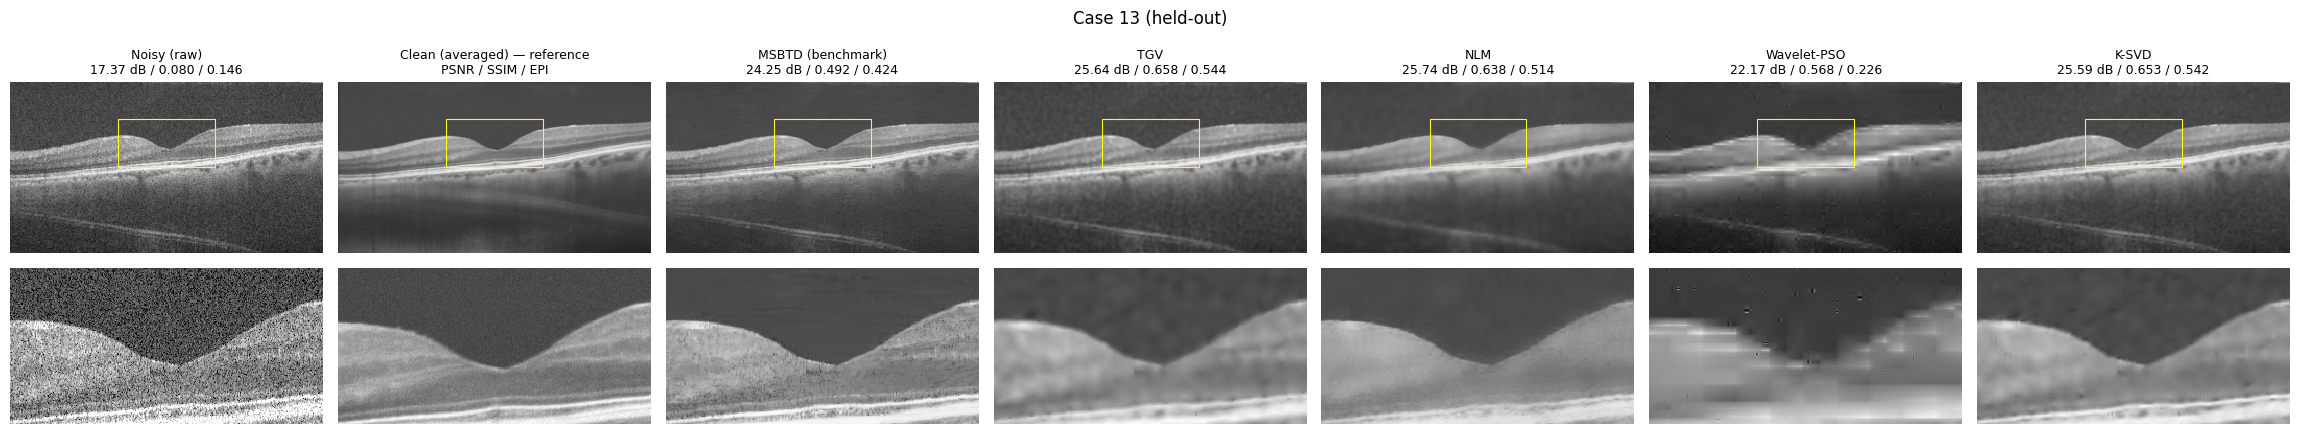

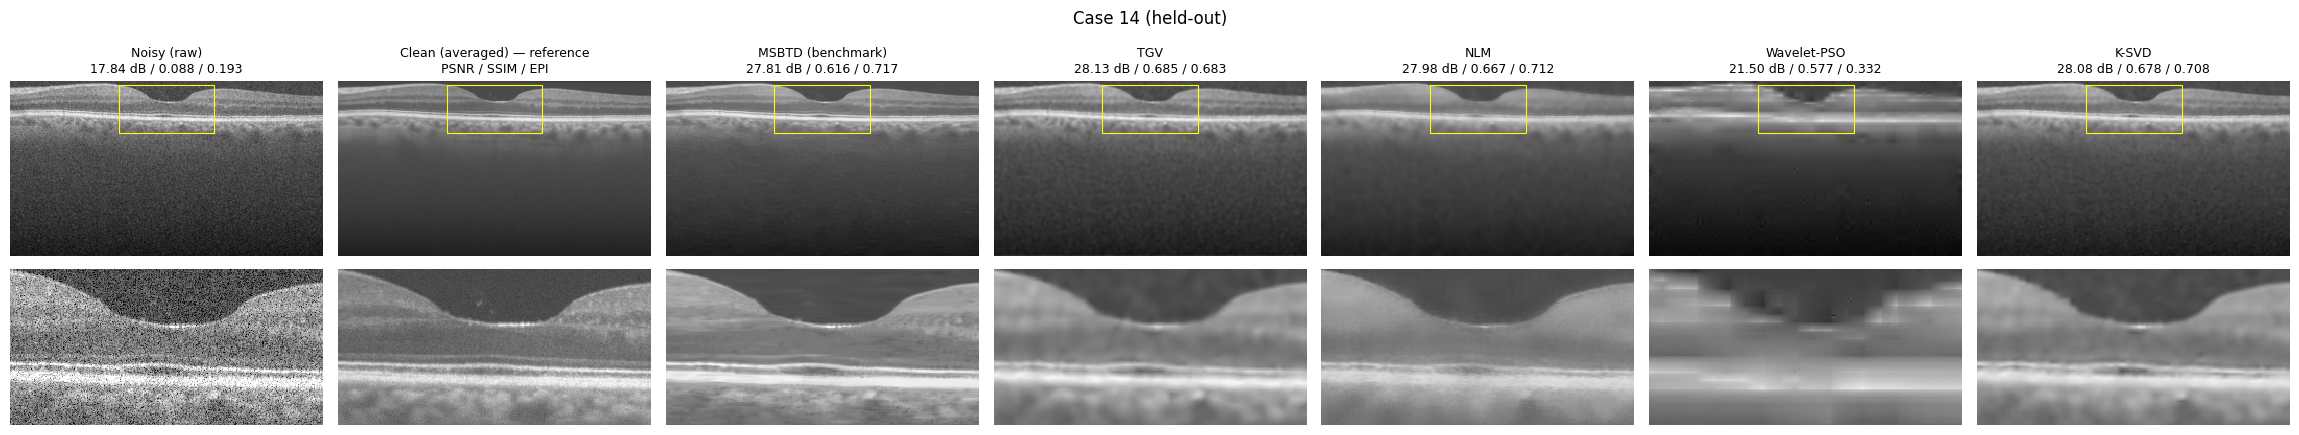

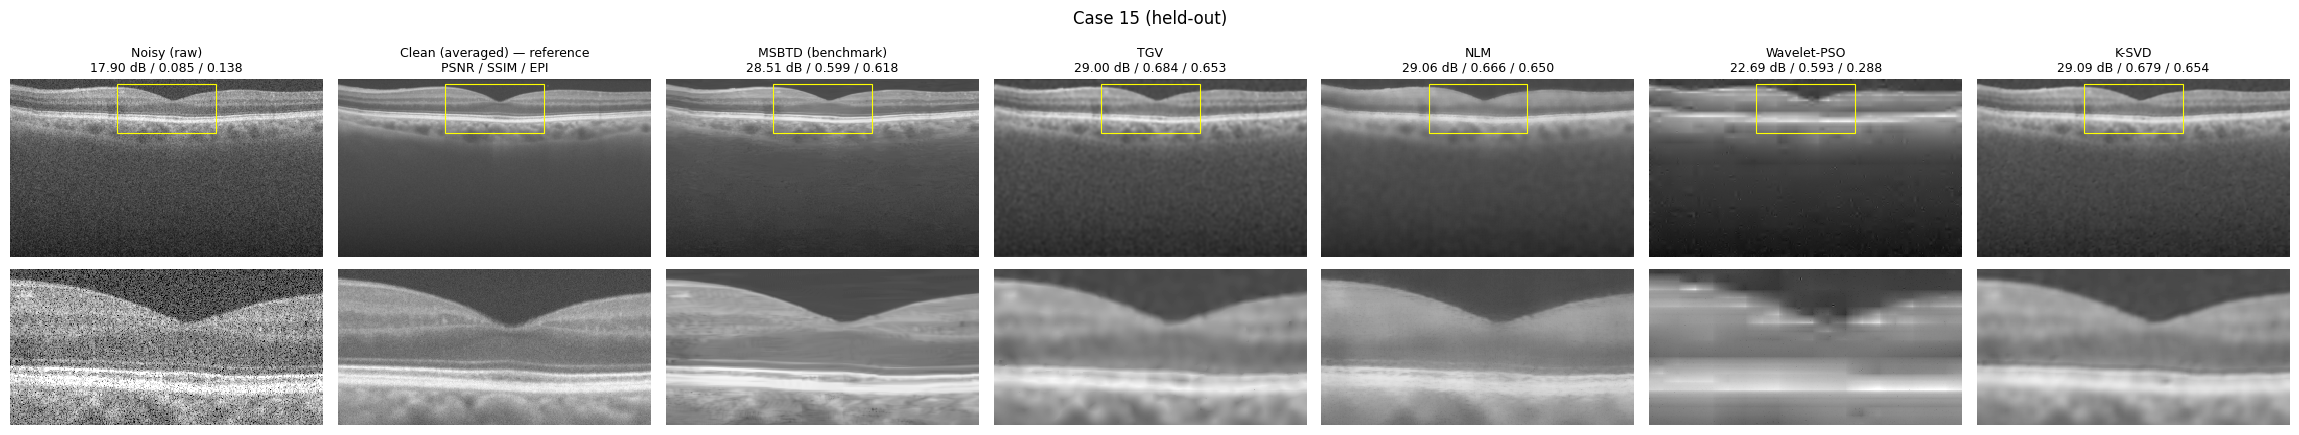

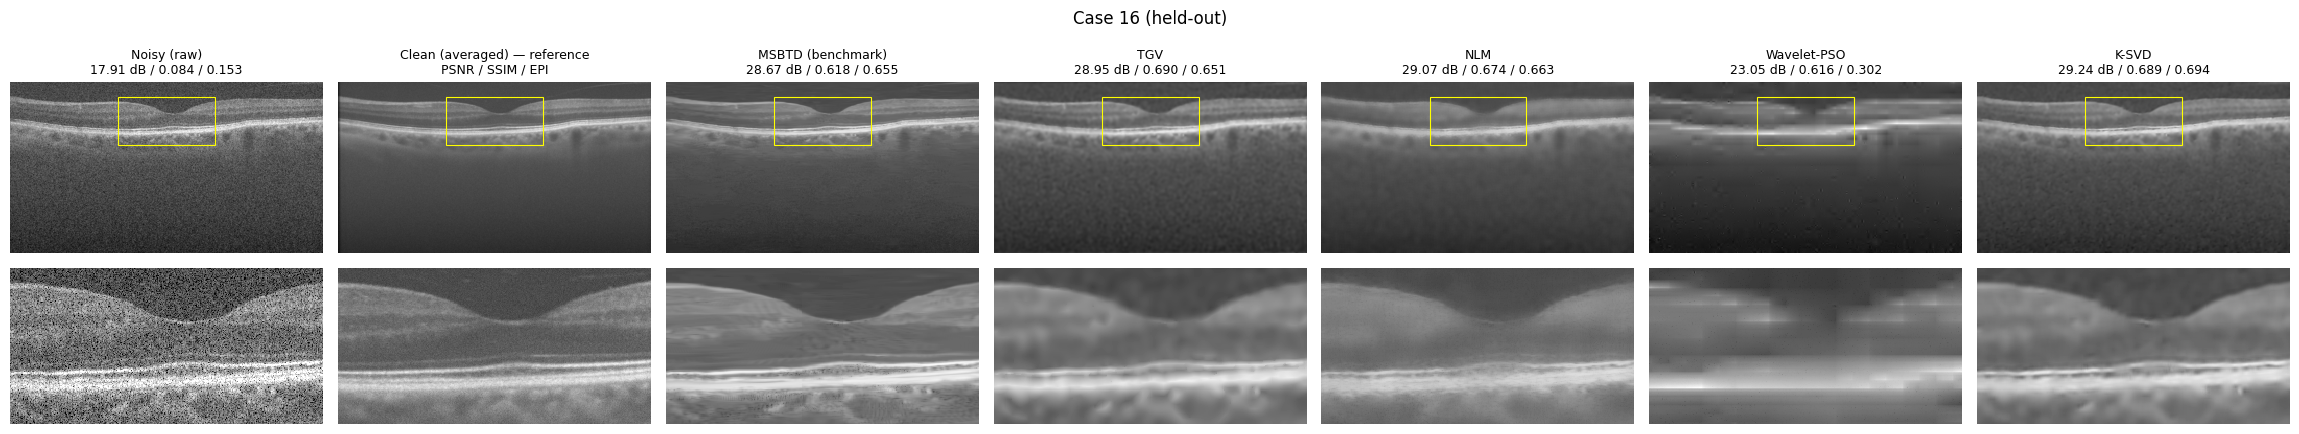

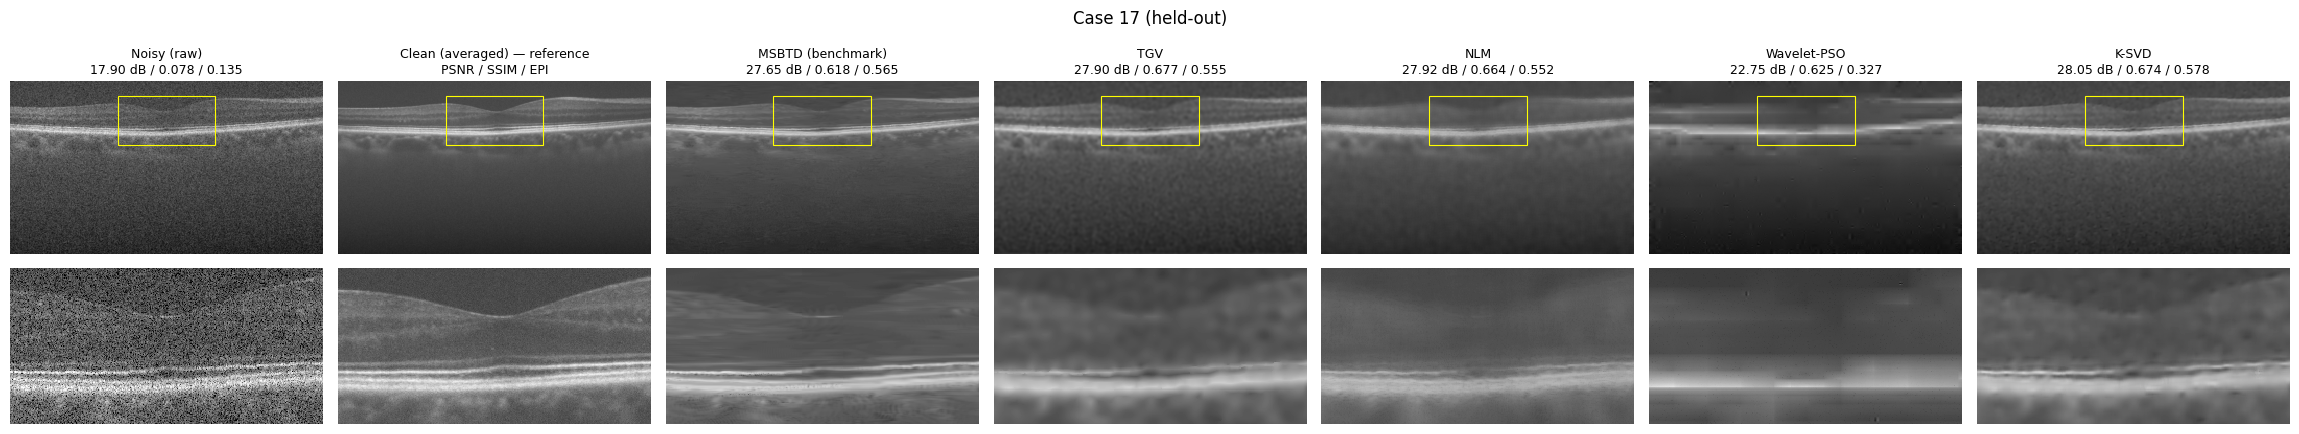

In [22]:
def zoom_box(ref, h=150, w=300):
    rows = np.convolve(ref.mean(axis=1), np.ones(15) / 15, mode="same")
    r0 = int(np.clip(rows.argmax() - 0.7 * h, 0, ref.shape[0] - h))
    c0 = (ref.shape[1] - w) // 2
    return slice(r0, r0 + h), slice(c0, c0 + w)


def show_case(cid):
    ref = REF[cid]
    panels = [("Noisy (raw)", RAW[cid]), ("Clean (averaged) — reference", ref), (f"{BENCH} (benchmark)", MSB[cid])]
    panels += [(m, OUTS[cid][m]) for m in METHODS]
    zr, zc = zoom_box(ref)
    fig, axes = plt.subplots(2, len(panels), figsize=(3.3 * len(panels), 4.6),
                             gridspec_kw={"height_ratios": [1, 0.9]})
    for j, (title, img) in enumerate(panels):
        if title.startswith("Clean"):
            sub = "PSNR / SSIM / EPI"
        else:
            mt = M.all_metrics(ref, img)
            sub = f"{mt['PSNR']:.2f} dB / {mt['SSIM']:.3f} / {mt['EPI']:.3f}"
        axes[0, j].imshow(img, vmin=0, vmax=255)
        axes[0, j].add_patch(plt.Rectangle((zc.start, zr.start), zc.stop - zc.start, zr.stop - zr.start,
                                           fill=False, ec="yellow", lw=0.8))
        axes[0, j].set_title(f"{title}\n{sub}", fontsize=9)
        axes[1, j].imshow(img[zr, zc], vmin=0, vmax=255, interpolation="nearest")
        for ax in axes[:, j]:
            ax.axis("off")
    fig.suptitle(f"Case {cid} (held-out)", fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "figures" / f"case{cid:02d}_comparison.png", dpi=110)
    plt.show()


for cid in TEST_IDS:
    show_case(cid)

### 6.1 What EPI is looking at

Sobel gradient-magnitude maps of the zoomed region for one held-out case. These are the maps whose correlation with
the reference's map (second panel) gives EPI. Residual speckle shows up as a field of short random edges. Smoothing
that goes too far shows up as faint or missing layer boundaries.

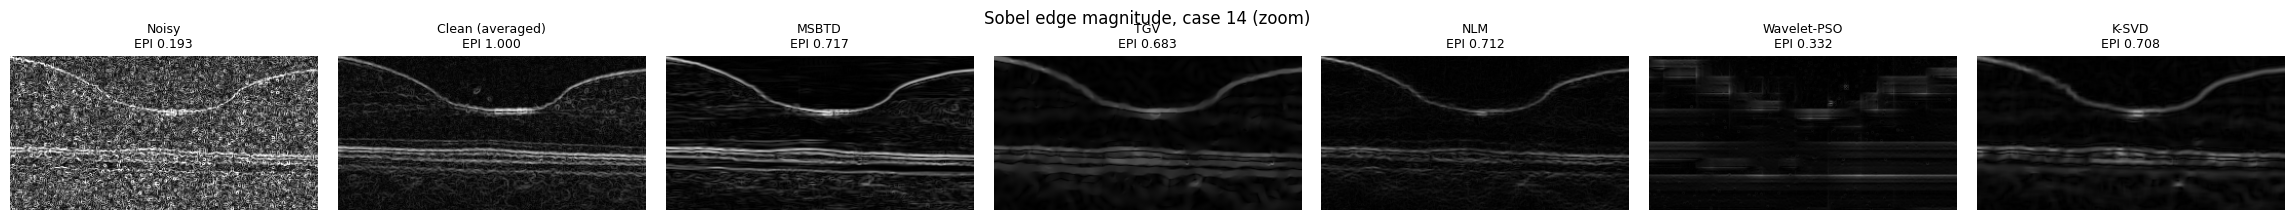

In [23]:
cid = TEST_IDS[1]
zr, zc = zoom_box(REF[cid])
panels = [("Noisy", RAW[cid]), ("Clean (averaged)", REF[cid]), (BENCH, MSB[cid])] + [(m, OUTS[cid][m]) for m in METHODS]
ref_edges = M._sobel_mag(REF[cid])[zr, zc]
fig, axes = plt.subplots(1, len(panels), figsize=(3.3 * len(panels), 2.2))
for ax, (title, img) in zip(axes, panels):
    ax.imshow(M._sobel_mag(img)[zr, zc], vmin=0, vmax=np.percentile(ref_edges, 99.5) * 1.5)
    ax.set_title(f"{title}\nEPI {M.epi(REF[cid], img):.3f}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"Sobel edge magnitude, case {cid} (zoom)")
plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "edge_maps.png", dpi=110)
plt.show()

## 7. Quantitative results

### 7.1 Held-out test set (cases 13–17): the primary comparison

In [24]:
def summary(df):
    s = df.groupby("method")[["PSNR", "SSIM", "EPI"]].agg(["mean", "std"]).loc[ALL]
    s.columns = [f"{m} {a}" for m, a in s.columns]
    return s


def per_image(df, metric):
    t = df.pivot(index="case", columns="method", values=metric)[ALL]
    t.loc["mean"] = t.mean()
    return t


test = RESULTS[RESULTS["set"] == "test"]
SUMMARY_TEST = summary(test)
SUMMARY_TEST.to_csv(OUT_DIR / "summary_test.csv")
print("Mean ± std over the 5 held-out cases (higher is better for all three metrics)")
display(SUMMARY_TEST.round(4))
for metric in ["PSNR", "SSIM", "EPI"]:
    print(f"\n{metric} per held-out case")
    display(per_image(test, metric).round(4))

Mean ± std over the 5 held-out cases (higher is better for all three metrics)


,PSNR mean,PSNR std,SSIM mean,SSIM std,EPI mean,EPI std
method,,,,,,
Noisy,17.7853,0.2355,0.0832,0.0042,0.1529,0.0234
MSBTD,27.3795,1.8045,0.5888,0.0546,0.5957,0.1108
TGV,27.9241,1.3685,0.6787,0.0126,0.6173,0.0632
NLM,27.9532,1.3586,0.6620,0.0138,0.6183,0.0822
Wavelet-PSO,22.4329,0.6093,0.5957,0.0244,0.2951,0.0426
K-SVD,28.0097,1.4603,0.6747,0.0136,0.6352,0.0726



PSNR per held-out case


method,Noisy,MSBTD,TGV,NLM,Wavelet-PSO,K-SVD
case,,,,,,
13,17.3669,24.2468,25.6358,25.7363,22.1719,25.5921
14,17.8419,27.8143,28.1342,27.9824,21.5023,28.0793
15,17.9044,28.5119,28.9992,29.0578,22.6870,29.0899
16,17.9118,28.6695,28.9506,29.0696,23.0546,29.2392
17,17.9013,27.6548,27.9008,27.9200,22.7486,28.0478
mean,17.7853,27.3795,27.9241,27.9532,22.4329,28.0097



SSIM per held-out case


method,Noisy,MSBTD,TGV,NLM,Wavelet-PSO,K-SVD
case,,,,,,
13,0.0800,0.4922,0.6579,0.6382,0.5684,0.6526
14,0.0884,0.6162,0.6849,0.6666,0.5766,0.6783
15,0.0853,0.5989,0.6836,0.6663,0.5925,0.6789
16,0.0843,0.6182,0.6903,0.6744,0.6162,0.6894
17,0.0779,0.6184,0.6770,0.6644,0.6249,0.6744
mean,0.0832,0.5888,0.6787,0.6620,0.5957,0.6747



EPI per held-out case


method,Noisy,MSBTD,TGV,NLM,Wavelet-PSO,K-SVD
case,,,,,,
13,0.1457,0.4240,0.5438,0.5145,0.2261,0.5418
14,0.1928,0.7167,0.6833,0.7120,0.3322,0.7083
15,0.1384,0.6178,0.6528,0.6504,0.2882,0.6540
16,0.1529,0.6553,0.6512,0.6630,0.3018,0.6939
17,0.1348,0.5645,0.5555,0.5516,0.3273,0.5782
mean,0.1529,0.5957,0.6173,0.6183,0.2951,0.6352


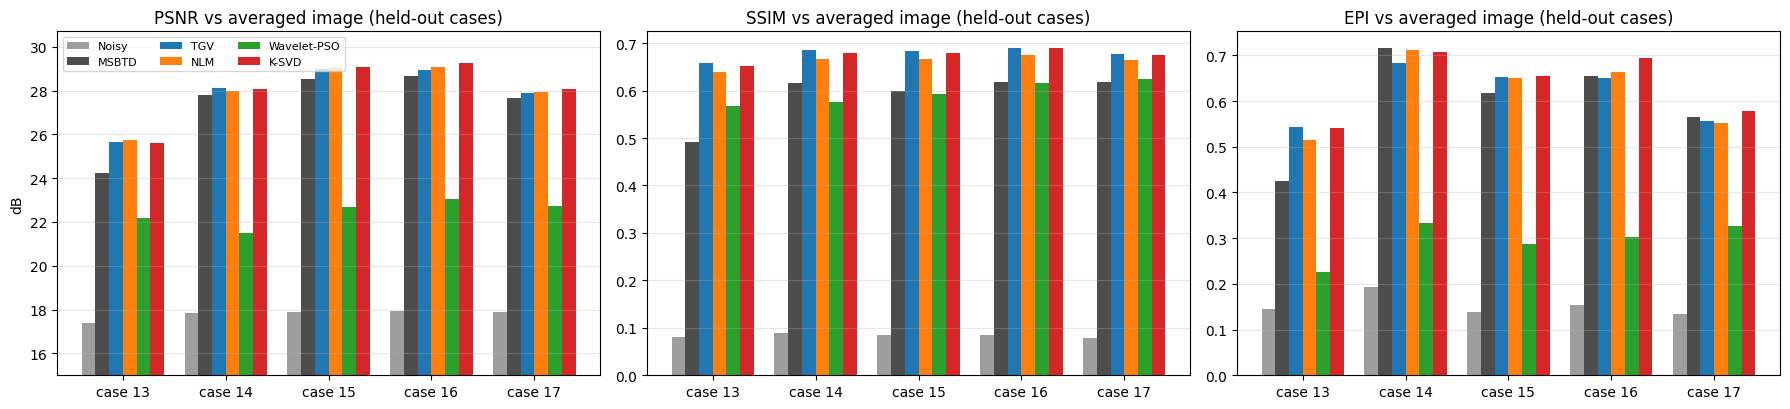

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, metric in zip(axes, ["PSNR", "SSIM", "EPI"]):
    piv = test.pivot(index="case", columns="method", values=metric)[ALL]
    x = np.arange(len(piv.index))
    w = 0.8 / len(ALL)
    for k, m in enumerate(ALL):
        ax.bar(x + (k - (len(ALL) - 1) / 2) * w, piv[m], w, label=m, color=COLORS[m])
    ax.set_xticks(x, [f"case {c}" for c in piv.index])
    ax.set_title(f"{metric} vs averaged image (held-out cases)")
    ax.grid(axis="y", alpha=0.3)
    if metric == "PSNR":
        ax.set_ylim(15, None)
        ax.set_ylabel("dB")
axes[0].legend(ncol=3, fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "metrics_test_bars.png", dpi=110)
plt.show()

*(results discussion is written after the first run)*

### 7.2 Second evaluation set (cases 2, 3, 5, 6, 8, 9, 11, 12) and paired comparison

The same frozen parameters on the eight untuned training cases. K-SVD's dictionary was learned from these cases'
*averaged* images, so a K-SVD advantage here would be suspect. If the ranking matches the held-out set, it isn't
driven by that leak. The paired table counts, over all 13 evaluation cases, how often each method beats the MSBTD
benchmark on each metric.

In [26]:
other = RESULTS[RESULTS["set"] == "other"]
SUMMARY_OTHER = summary(other)
SUMMARY_OTHER.to_csv(OUT_DIR / "summary_other.csv")
print("Mean ± std over the 8 untuned training cases")
display(SUMMARY_OTHER.round(4))

rank = (RESULTS[RESULTS["method"].isin(METHODS + [BENCH])]
        .assign(**{f"{m} rank": lambda d, m=m: d.groupby("case")[m].rank(ascending=False) for m in ["PSNR", "SSIM", "EPI"]})
        .groupby("method")[[f"{m} rank" for m in ["PSNR", "SSIM", "EPI"]]].mean().loc[[BENCH] + METHODS])
print("Mean rank among the five denoised outputs over all 13 evaluation cases (1 = best)")
display(rank.round(2))

wide = RESULTS.pivot(index="case", columns="method", values=["PSNR", "SSIM", "EPI"])
paired = pd.DataFrame({m: {f"{k} wins vs {BENCH}": f"{int((wide[k][m] > wide[k][BENCH]).sum())}/{len(wide)}"
                           for k in ["PSNR", "SSIM", "EPI"]}
                       | {f"mean Δ{k}": (wide[k][m] - wide[k][BENCH]).mean().round(4) for k in ["PSNR", "SSIM", "EPI"]}
                       for m in METHODS}).T
display(paired)

Mean ± std over the 8 untuned training cases


,PSNR mean,PSNR std,SSIM mean,SSIM std,EPI mean,EPI std
method,,,,,,
Noisy,17.7493,0.4670,0.0790,0.0070,0.1233,0.0658
MSBTD,26.3090,2.1920,0.5739,0.0929,0.4649,0.1649
TGV,26.9941,2.0436,0.6735,0.0780,0.5426,0.1372
NLM,27.0194,2.0956,0.6569,0.0771,0.5085,0.1644
Wavelet-PSO,22.2794,1.9177,0.6056,0.0792,0.2745,0.0625
K-SVD,27.0115,2.0967,0.6672,0.0772,0.5426,0.1751


Mean rank among the five denoised outputs over all 13 evaluation cases (1 = best)


,PSNR rank,SSIM rank,EPI rank
method,,,
MSBTD,3.85,4.69,3.38
TGV,2.15,1.00,2.15
NLM,2.15,2.92,2.85
Wavelet-PSO,5.00,4.31,5.00
K-SVD,1.85,2.08,1.62


,PSNR wins vs MSBTD,SSIM wins vs MSBTD,EPI wins vs MSBTD,mean ΔPSNR,mean ΔSSIM,mean ΔEPI
TGV,13/13,13/13,9/13,0.6311,0.0958,0.0561
NLM,12/13,13/13,10/13,0.6578,0.0792,0.0355
Wavelet-PSO,0/13,9/13,0/13,-4.3823,0.0221,-0.2328
K-SVD,12/13,13/13,12/13,0.6747,0.0904,0.063


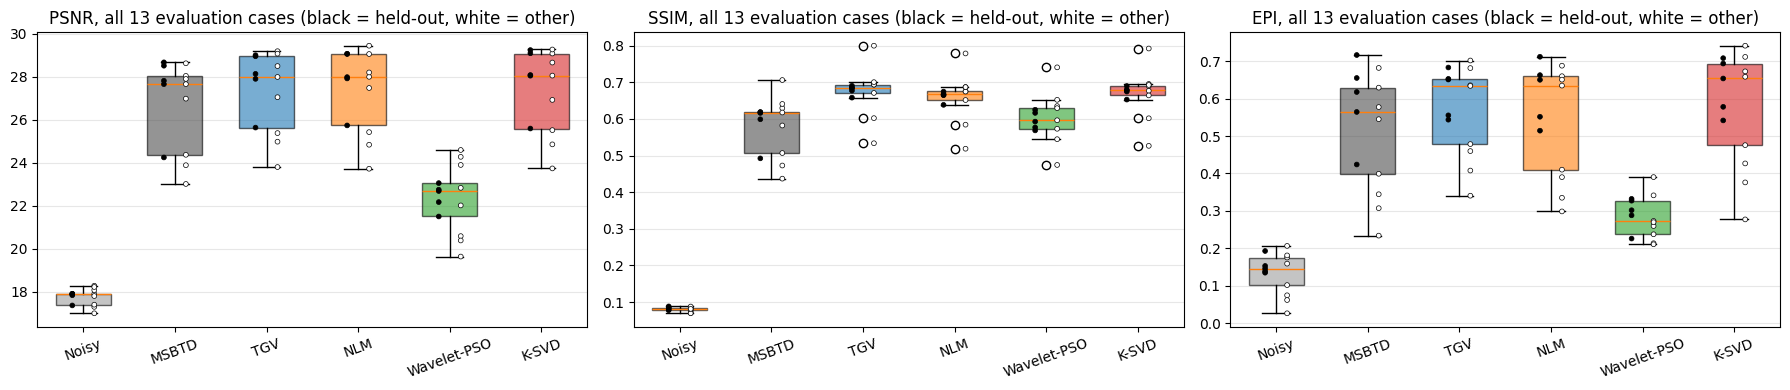

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, ["PSNR", "SSIM", "EPI"]):
    data = [RESULTS.loc[RESULTS["method"] == m, metric] for m in ALL]
    bp = ax.boxplot(data, tick_labels=ALL, patch_artist=True, widths=0.6)
    for patch, m in zip(bp["boxes"], ALL):
        patch.set_facecolor(COLORS[m])
        patch.set_alpha(0.6)
    for k, m in enumerate(ALL):
        sub = RESULTS[RESULTS["method"] == m]
        ax.scatter(np.full(len(sub), k + 1) + np.where(sub["set"] == "test", -0.12, 0.12), sub[metric],
                   s=12, c=np.where(sub["set"] == "test", "k", "w"), edgecolors="k", lw=0.5, zorder=3)
    ax.set_title(f"{metric}, all 13 evaluation cases (black = held-out, white = other)")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "metrics_all_boxplot.png", dpi=110)
plt.show()

*(results discussion is written after the first run)*

### 7.3 Runtime

Wall-clock seconds per B-scan (≈ 540×960) with the tuned parameters, measured while several images were processed
in parallel threads (8 for TGV / NLM, 2 for K-SVD), so they are slower than a run on an idle machine. The K-SVD figure excludes dictionary learning,
which happens once (≈ 80 s in the K-SVD notebook) and is reused for every image. The Wavelet-PSO figure excludes the
one-off PSO search. MSBTD timing isn't available because its results are precomputed.

In [28]:
rt = pd.DataFrame(TIMES).groupby("method")["seconds"].agg(["mean", "std", "min", "max"]).loc[METHODS]
display(rt.round(2))

,mean,std,min,max
method,,,,
TGV,33.52,8.29,22.09,43.78
NLM,22.23,5.54,14.81,27.60
Wavelet-PSO,0.09,0.02,0.07,0.11
K-SVD,4.21,0.88,3.26,6.18


## 8. Why balancing mattered: each method with its original settings

The same held-out cases, run with the parameters each implementation shipped with:

| Method | Original settings |
|---|---|
| TGV | $\alpha_0=\alpha_1=\beta=0.1$, $\lambda_{1,2,3}=2$ (chosen on a synthetic phantom) |
| NLM | $h_f=3.6$, $\alpha=0.5$ (tuned on Image 1 in the NLM notebook) |
| Wavelet-PSO | $L=1$, $\log(1+z)$ before the DWT, PSO fitness vs the **noisy input**, which converges to $(\alpha,\beta,K)=(0.5,5,1)$ on every image in the PSO notebook |
| K-SVD | $C=1.15$, $\lambda=30/\sigma$ (paper constants) |

In [29]:
ORIGINAL = {"TGV": {"alpha": 0.1, "beta": 0.1}, "NLM": {"h_factor": 3.6, "alpha": 0.5},
            "Wavelet-PSO": {"level": 1, "alpha": 0.5, "beta": 5.0, "K": 1.0, "log_domain": False},
            "K-SVD": {"omp_C": 1.15, "lambda_scale": 30.0}}
log("re-running the held-out cases with each method's original settings")
orig = pd.DataFrame([{"method": m, "case": cid, **res[0]}
                     for m in METHODS
                     for cid, res in zip(TEST_IDS, parallel(m, M.score, [(DISPATCH[m], RAW[c], REF[c], ORIGINAL[m])
                                                                          for c in TEST_IDS]))])
orig_mean = orig.groupby("method")[["PSNR", "SSIM", "EPI"]].mean().loc[METHODS]
tuned_mean = test.groupby("method")[["PSNR", "SSIM", "EPI"]].mean().loc[METHODS]
before_after = pd.concat({"original settings": orig_mean, "balanced tuning": tuned_mean,
                          "change": tuned_mean - orig_mean}, axis=1)
before_after.to_csv(OUT_DIR / "original_vs_balanced.csv")
print("Mean over the 5 held-out cases")
display(before_after.round(4))

[   936s] re-running the held-out cases with each method's original settings


TypeError: wavelet_mst() got an unexpected keyword argument 'log_domain'

*(results discussion is written after the first run)*

*(results discussion is written after the first run)*

In [ ]:
log("done")
print("written to", OUT_DIR.resolve())
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file() and p.parent.name != "denoised":
        print("  ", p.relative_to(OUT_DIR))

[  1081s] done
written to C:\Users\sidhe\oct_denoising\Comparison\outputs
   figures\case13_comparison.png
   figures\case14_comparison.png
   figures\case15_comparison.png
   figures\case16_comparison.png
   figures\case17_comparison.png
   figures\edge_maps.png
   figures\metrics_all_boxplot.png
   figures\metrics_test_bars.png
   figures\tuning_curves.png
   metrics_per_image.csv
   original_vs_balanced.csv
   run_log.txt
   summary_other.csv
   summary_test.csv
